In [20]:
%pip install scikit-learn pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [22]:
tips = pd.read_csv("tips.csv")

print("First five rows:")
print(tips.head())

print("\nDataset shape:", tips.shape)

X = tips[["total_bill"]]
y = tips["tip"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

First five rows:
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4

Dataset shape: (244, 7)
Training rows: 170
Testing rows: 74


In [23]:
regression = LinearRegression()

regression.fit(X_train, y_train)

slope = regression.coef_[0]
intercept = regression.intercept_

print("Slope:", round(slope, 4))
print("Intercept:", round(intercept, 4))
print("Test R-squared:", round(regression.score(X_test, y_test), 4))

Slope: 0.1089
Intercept: 0.877
Test R-squared: 0.4292


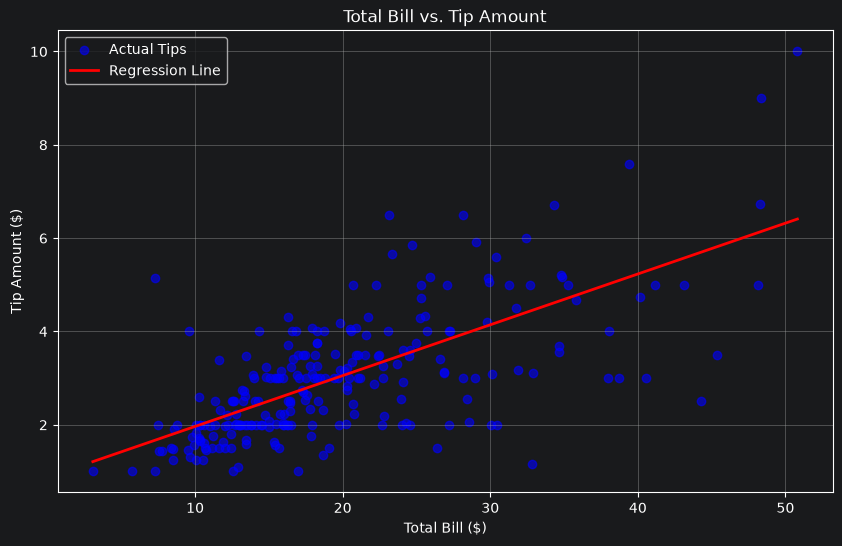

In [24]:
plt.figure(figsize=(10, 6))

plt.scatter(
    X["total_bill"],
    y,
    color="blue",
    alpha=0.6,
    label="Actual Tips"
)

sorted_X = X.sort_values("total_bill")
predicted_tips = regression.predict(sorted_X)

plt.plot(
    sorted_X["total_bill"],
    predicted_tips,
    color="red",
    linewidth=2,
    label="Regression Line"
)

plt.title("Total Bill vs. Tip Amount")
plt.xlabel("Total Bill ($)")
plt.ylabel("Tip Amount ($)")
plt.legend()
plt.grid(True)

plt.show()

In [25]:
iris = load_iris(as_frame=True)

X_iris = iris.data
y_iris = iris.target

print("Total flowers:", len(X_iris))
print("\nFeatures:")
print(X_iris.head())

X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(
    X_iris,
    y_iris,
    test_size=0.30,
    random_state=42
)

print("\nTraining flowers:", len(X_train_iris))
print("Testing flowers:", len(X_test_iris))

Total flowers: 150

Features:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Training flowers: 105
Testing flowers: 45


In [26]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_iris, y_train_iris)

knn_predictions = knn.predict(X_test_iris)

knn_accuracy = accuracy_score(
    y_test_iris,
    knn_predictions
)

print("kNN Test Accuracy:", round(knn_accuracy, 4))

kNN Test Accuracy: 1.0


Decision Tree Test Accuracy: 1.0


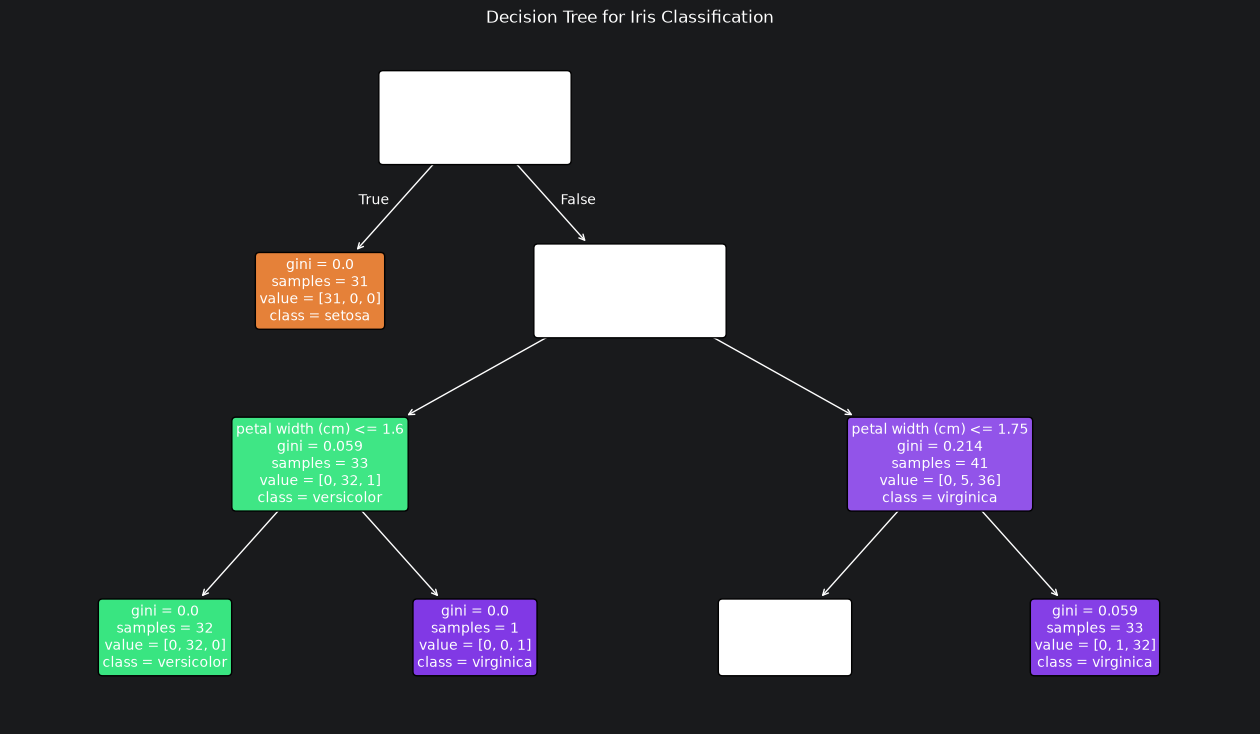

Root feature: petal length (cm)
Root threshold: 2.45


In [27]:
tree = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

tree.fit(X_train_iris, y_train_iris)

tree_accuracy = tree.score(
    X_test_iris,
    y_test_iris
)

print("Decision Tree Test Accuracy:", round(tree_accuracy, 4))

plt.figure(figsize=(16, 9))

plot_tree(
    tree,
    feature_names=X_iris.columns,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree for Iris Classification")
plt.show()

print(
    "Root feature:",
    X_iris.columns[tree.tree_.feature[0]]
)
print(
    "Root threshold:",
    round(tree.tree_.threshold[0], 2)
)

In [28]:
# Step 7: Decision Tree Interpretation

# The decision tree uses flower measurements to predict the iris species. Its first decision separates flowers based on a petal measurement, helping identify which species the flower most likely belongs to.

In [29]:
unlimited_tree = DecisionTreeClassifier(
    random_state=42
)

unlimited_tree.fit(X_train_iris, y_train_iris)

comparison = pd.DataFrame({
    "Model": [
        "Shallow Tree",
        "Unlimited Tree"
    ],
    "Training Accuracy": [
        tree.score(X_train_iris, y_train_iris),
        unlimited_tree.score(X_train_iris, y_train_iris)
    ],
    "Testing Accuracy": [
        tree.score(X_test_iris, y_test_iris),
        unlimited_tree.score(X_test_iris, y_test_iris)
    ]
})

print("Model Comparison:")
print(comparison.round(3).to_string(index=False))

Model Comparison:
         Model  Training Accuracy  Testing Accuracy
  Shallow Tree              0.952               1.0
Unlimited Tree              1.000               1.0


In [30]:
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X_iris.columns
)

prediction = knn.predict(new_flower)

species = iris.target_names[prediction[0]]

print("New Flower Measurements:")
print(new_flower)

print("\nPredicted Species:", species)

New Flower Measurements:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2

Predicted Species: setosa


In [31]:
print("Final Model Test Scores")
print("-----------------------")
print(f"kNN: {knn_accuracy:.2%}")
print(f"Shallow Decision Tree: {tree_accuracy:.2%}")
print(f"Unlimited Decision Tree: {unlimited_tree.score(X_test_iris, y_test_iris):.2%}")

best_model = (
    "kNN" if knn_accuracy > tree_accuracy
    else "Shallow Decision Tree"
)

print("\nSuggested model:", best_model)

Final Model Test Scores
-----------------------
kNN: 100.00%
Shallow Decision Tree: 100.00%
Unlimited Decision Tree: 100.00%

Suggested model: Shallow Decision Tree
